# Breast Cancer Classification — Train, Evaluate, Save

**Run this notebook in Jupyter Notebook or Google Colab, not VS Code.**

1. Download `data.csv` from the Kaggle dataset linked in the README.
2. Upload it to the same folder as this notebook (in Colab, upload it to the current runtime).
3. Run every cell in order.
4. This notebook writes `model.joblib` and `feature_names.json` into the current working directory. Copy both files into the VS Code project root after training in Colab.

Educational demo only; not for medical diagnosis.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_score, recall_score, f1_score
)
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
DATA_PATH = Path("data.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "data.csv not found. Download it from Kaggle and upload/place it beside this notebook."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN



Columns:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']


In [2]:
# Clean column names and remove empty unnamed columns.
df.columns = [str(c).strip() for c in df.columns]
df = df.loc[:, ~df.columns.str.match(r"^Unnamed")]

if "diagnosis" not in df.columns:
    raise ValueError("Expected a 'diagnosis' target column. Check that you downloaded the Kaggle WDBC data.csv.")

# The dataset uses B = benign and M = malignant.
df["diagnosis"] = df["diagnosis"].astype(str).str.strip().str.upper()
df = df[df["diagnosis"].isin(["B", "M"])].copy()

# Drop identifiers; keep the diagnosis target separate.
drop_columns = [c for c in ["id", "ID", "diagnosis"] if c in df.columns]
X = df.drop(columns=drop_columns + (["diagnosis"] if "diagnosis" not in drop_columns else []), errors="ignore")
y = df["diagnosis"]

# Convert features to numeric and remove any columns that contain no numeric values.
X = X.apply(pd.to_numeric, errors="coerce")
X = X.dropna(axis=1, how="all")
# Median imputation for any remaining missing values.
X = X.fillna(X.median(numeric_only=True))

if X.shape[1] != 30:
    print(f"Warning: found {X.shape[1]} feature columns rather than the expected 30. Verify the dataset version.")

feature_names = X.columns.tolist()
print("Number of model features:", len(feature_names))
print("Class distribution:")
display(y.value_counts().rename_axis("diagnosis").to_frame("count"))

Number of model features: 30
Class distribution:


,count
diagnosis,
B,357
M,212


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(f"Test accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Test precision (M positive): {precision_score(y_test, y_pred, pos_label='M'):.4f}")
print(f"Test recall (M positive):    {recall_score(y_test, y_pred, pos_label='M'):.4f}")
print(f"Test F1 (M positive):        {f1_score(y_test, y_pred, pos_label='M'):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, labels=["B", "M"], target_names=["Benign (B)", "Malignant (M)"]))

Test accuracy:  0.9649
Test precision (M positive): 1.0000
Test recall (M positive):    0.9048
Test F1 (M positive):        0.9500

Classification report:
               precision    recall  f1-score   support

   Benign (B)       0.95      1.00      0.97        72
Malignant (M)       1.00      0.90      0.95        42

     accuracy                           0.96       114
    macro avg       0.97      0.95      0.96       114
 weighted avg       0.97      0.96      0.96       114



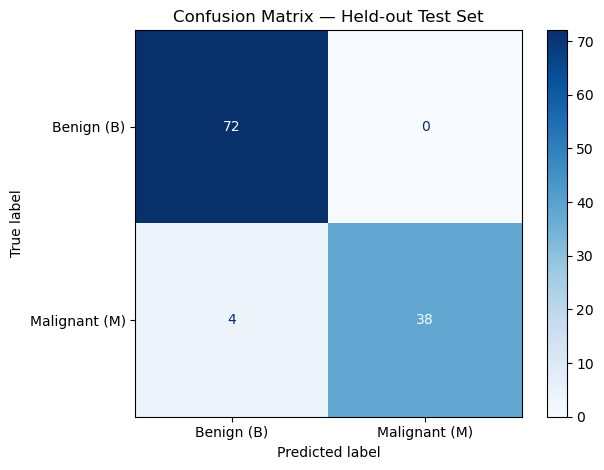

In [4]:
cm = confusion_matrix(y_test, y_pred, labels=["B", "M"])
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Benign (B)", "Malignant (M)"])
display.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Held-out Test Set")
plt.tight_layout()
plt.show()

In [5]:
# Save the trained model and exact feature order for the API.
joblib.dump(model, "model.joblib")
Path("feature_names.json").write_text(json.dumps(feature_names, indent=2), encoding="utf-8")

print("Saved model.joblib")
print("Saved feature_names.json")
print("Feature count:", len(feature_names))
print("\nCopy these two files into the root of your VS Code project.")


Saved model.joblib
Saved feature_names.json
Feature count: 30

Copy these two files into the root of your VS Code project.
